# Đánh giá L7-PUCT

Dùng **Run All** để xem bộ kết quả A5 đã có. Để chơi thêm các ván mới, bật `RUN_NEW` ở phần cấu hình. Lần chạy mới đo sức chơi và thời gian suy nghĩ trên cùng tập khai cuộc, với mỗi khai cuộc được chơi hai lần đổi X/O.

Chọn kernel Python của dự án (`.venv`). Notebook dùng pandas và Matplotlib có trong nhóm phụ thuộc `analysis` (`uv sync --extra analysis`). Chỉ phần chạy ván mới cần PyTorch và checkpoint.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "caro").is_dir() and (p / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án CaroGame hoặc thư mục con.")

OLD_RESULTS = ROOT / "runs/eval/a5_puct/results.csv"
RUNS = ROOT / "runs/eval/l7_notebook"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Xem kết quả A5 đã lưu

Điểm = (thắng + 0,5 × hòa) / tổng số ván. Vạch sai số là khoảng Wilson **do lần chạy cũ ghi lại**. Chỉ có số liệu tổng hợp, nên không thể tính lại khoảng theo cặp khai cuộc hoặc suy ra thời gian từ file này.

,agent,opponent,n,wins,draws,losses,score,ci_low,ci_high
0,l5_policy_sl,l2_rule,200,130,2,68,65.5%,58.7%,71.7%
1,l5_policy_sl,l3_alphabeta,200,41,2,157,21.0%,15.9%,27.2%
2,l6_policy_rl,l2_rule,200,151,5,44,76.8%,70.4%,82.1%
3,l6_policy_rl,l3_alphabeta,200,54,19,127,31.8%,25.7%,38.5%
4,"L7-PUCT[l5,100]",l3_alphabeta,200,88,9,103,46.2%,39.5%,53.2%
5,"L7-PUCT[l5,200]",l3_alphabeta,200,104,26,70,58.5%,51.6%,65.1%
6,"L7-PUCT[l5,400]",l3_alphabeta,200,105,34,61,61.0%,54.1%,67.5%
7,"L7-PUCT[l5,800]",l3_alphabeta,200,118,32,50,67.0%,60.2%,73.1%
8,"L7-PUCT[l5,200]",l2_rule,200,175,1,24,87.8%,82.5%,91.6%
9,"L7-PUCT[l6,200]",l3_alphabeta,200,105,21,74,57.8%,50.8%,64.4%


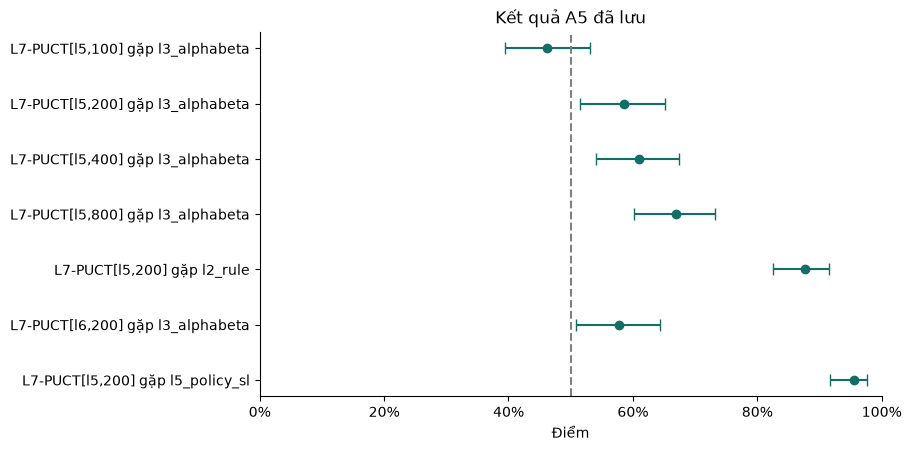

In [2]:
if OLD_RESULTS.is_file():
    old = pd.read_csv(OLD_RESULTS)
    l7 = old[old["agent"].str.startswith("L7-PUCT")].copy()
    display(old.style.format({"score": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))

    labels = l7["agent"] + " gặp " + l7["opponent"]
    fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
    y = np.arange(len(l7))
    ax.errorbar(
        l7["score"], y,
        xerr=[l7["score"] - l7["ci_low"], l7["ci_high"] - l7["score"]],
        fmt="o", color="#136e65", capsize=4,
    )
    ax.set(yticks=y, yticklabels=labels, xlim=(0, 1), xlabel="Điểm", title="Kết quả A5 đã lưu")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.axvline(0.5, color="0.5", linestyle="--")
    ax.invert_yaxis()
    plt.show()
else:
    print(f"Chưa có dữ liệu A5 ở {OLD_RESULTS.relative_to(ROOT)}.")

## Chọn cấu hình đánh giá mới

Bắt đầu với 10 khai cuộc để kiểm tra pipeline và 400 mô phỏng là mức cao nhất trong lượt chạy thử mặc định. Khi cần kết luận, tăng lên 50–100 khai cuộc, giữ cùng seed và độ sâu L3 cho các cấu hình cần so sánh. Để đo ảnh hưởng của việc tìm kiếm, notebook cũng chạy policy không tìm kiếm với từng checkpoint được chọn.

Mỗi cấu hình đấu với cùng danh sách đối thủ. Có thể thêm `"L2"` để kiểm tra thêm một mốc sức chơi. Thời gian đo theo từng nước trong một tiến trình, với một luồng nội bộ PyTorch. Đọc lại kết quả bằng cách đặt `READ_RUN` thành tên thư mục mà phần chạy in ra.

In [3]:
RUN_NEW = False
READ_RUN = None  # ví dụ: "20261121-153012-123456"

SEED = 42
N_OPENINGS = 10
SIMS = (100, 200, 400)  # thêm 800 để thử ngân sách cao hơn
CHECKPOINTS = ("l5",)  # thêm "l6" để so sánh mạng RL
OPPONENTS = ("L3",)   # có thể thêm "L2"
L3_DEPTH = 6
TORCH_THREADS = 1

In [4]:
from datetime import datetime


def run_eval(output_root):
    import platform

    import torch

    from caro.agents import make_agent
    from caro.arena.match import play_match
    from caro.config import load_manifest, resolve_agent
    from caro.engine.game import CaroGame

    openings = json.loads((ROOT / "runs/openings/openings_v1.json").read_text())
    if not 1 <= N_OPENINGS <= len(openings):
        raise ValueError(f"N_OPENINGS phải nằm trong [1, {len(openings)}].")
    if not SIMS or min(SIMS) < 1 or len(set(SIMS)) != len(SIMS):
        raise ValueError("SIMS phải chứa các ngân sách dương và không trùng.")
    if not CHECKPOINTS or not OPPONENTS or len(set(CHECKPOINTS)) != len(CHECKPOINTS) or len(set(OPPONENTS)) != len(OPPONENTS):
        raise ValueError("CHECKPOINTS và OPPONENTS phải có phần tử và không trùng.")

    ids = np.random.default_rng(SEED).permutation(len(openings))[:N_OPENINGS].tolist()
    openings_by_id = {i: openings[i] for i in ids}
    torch.set_num_threads(TORCH_THREADS)

    candidates = {}
    policy_configs = {"l5": "agents/l5_policy_sl", "l6": "agents/l6_policy_rl"}
    for ck in CHECKPOINTS:
        candidates[f"Policy {ck}"] = resolve_agent(policy_configs[ck])
        for sims in SIMS:
            spec = resolve_agent("agents/l7_puct")
            spec["params"]["checkpoint"] = f"model:{ck}"
            spec["limits"] = {"mode": "fixed", "max_sims": sims}
            candidates[f"L7 {ck}/{sims}"] = spec

    opponent_configs = {
        "L2": resolve_agent("agents/l2_rule"),
        "L3": resolve_agent("agents/l3_alphabeta"),
    }
    opponent_configs["L3"]["limits"] = {"mode": "fixed", "max_depth": L3_DEPTH}
    opponent_specs = {name: opponent_configs[name] for name in OPPONENTS}
    opponents = {name: make_agent(spec) for name, spec in opponent_specs.items()}

    folder = output_root / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    folder.mkdir(parents=True)
    total = 2 * len(ids) * len(candidates) * len(opponents)
    meta = {
        "seed": SEED, "openings": openings_by_id, "expected_games": total,
        "candidates": candidates, "opponents": opponent_specs,
        "models": load_manifest(), "torch": torch.__version__,
        "platform": platform.platform(), "torch_threads": TORCH_THREADS,
    }
    (folder / "meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    print(f"Lượt chạy {folder.name} · {total} ván", flush=True)

    done = 0
    with (folder / "games.jsonl").open("x", encoding="utf-8") as log:
        for label, spec in candidates.items():
            candidate = make_agent(spec)
            for opponent_index, (opponent_name, opponent) in enumerate(opponents.items()):
                for i in ids:
                    opening = openings_by_id[i]
                    first_side = CaroGame.from_moves(opening).side
                    for side in (0, 1):
                        x, o = (candidate, opponent) if side == 0 else (opponent, candidate)
                        game_id = 2 * (opponent_index * len(openings) + i) + side
                        match = play_match(x, o, opening, SEED, game_id)
                        if match["result"] is None:
                            raise RuntimeError(f"Ván {game_id} chưa kết thúc.")
                        offset = int(side != first_side)
                        result = match["result"] * (1 if side == 0 else -1)
                        row = {
                            "candidate": label, "opponent": opponent_name, "opening_id": i,
                            "color": "X" if side == 0 else "O", "result": result,
                            "score": (1 + result) / 2, "moves": match["moves"],
                            "termination": match["termination"], "game_id": game_id,
                            "candidate_ms": match["time_ms"][offset::2],
                            "candidate_sims": match["sims"][offset::2],
                        }
                        log.write(json.dumps(row) + "\n")
                        done += 1
                    log.flush()
                    if done % 20 == 0 or done == total:
                        print(f"{done}/{total} ván · {label} gặp {opponent_name}", flush=True)
    return folder


run_folder = None
if RUN_NEW:
    run_folder = run_eval(RUNS)
elif READ_RUN:
    run_folder = RUNS / READ_RUN

## Phân tích ván mới

Khoảng tin cậy 95% được ước lượng bằng bootstrap theo **khai cuộc**, giữ hai màu của cùng khai cuộc đi cùng nhau. Khi so sánh hai cấu hình với cùng đối thủ, dùng chênh lệch trên từng khai cuộc trước khi bootstrap. Với quá ít khai cuộc, khoảng bootstrap có thể hẹp giả tạo hoặc suy biến, nên kết quả chạy thử chỉ dùng để kiểm tra quy trình.

Thời gian P50/P95 được tính từ các nước do tác tử được đánh giá chọn, bỏ các nước khai cuộc có sẵn. So sánh chi phí thời gian trong cùng một lượt chạy và trên cùng máy.

In [5]:
def opening_ci(values, indices):
    estimates = values[indices].mean(axis=1)
    return np.quantile(estimates, [0.025, 0.975])


def report(games):
    rows, deltas = [], []
    for opponent, group in games.groupby("opponent", sort=False):
        paired = group.groupby(["opening_id", "candidate"])["score"].mean().unstack()
        if paired.isna().any().any():
            raise ValueError(f"Có cấu hình thiếu khai cuộc khi gặp {opponent}.")
        ids = np.random.default_rng(99).integers(0, len(paired), size=(5_000, len(paired)))

        for label, trial in group.groupby("candidate", sort=False):
            samples = paired[label].to_numpy()
            low, high = opening_ci(samples, ids) if len(paired) >= 2 else (np.nan, np.nan)
            times = np.concatenate(trial["candidate_ms"].to_list())
            p50, p95 = np.quantile(times, [0.5, 0.95]) if times.size else (np.nan, np.nan)
            colors = trial.groupby("color")["score"].mean()
            rows.append({
                "Cấu hình": label, "Đối thủ": opponent, "Ván": len(trial),
                "Thắng": (trial["result"] == 1).sum(), "Hòa": (trial["result"] == 0).sum(),
                "Thua": (trial["result"] == -1).sum(), "Điểm": samples.mean(),
                "KTC dưới": low, "KTC trên": high,
                "Điểm X": colors["X"], "Điểm O": colors["O"], "P50 ms": p50, "P95 ms": p95,
            })
            if label.startswith("L7 "):
                model = label.split()[1].split("/")[0]
                baseline = f"L7 {model}/200"
                if baseline == label or baseline not in paired:
                    baseline = f"Policy {model}"
                baselines = [baseline]
                if model == "l6":
                    same_budget = label.replace("L7 l6/", "L7 l5/", 1)
                    if same_budget in paired:
                        baselines.append(same_budget)
                for reference in baselines:
                    diff = samples - paired[reference].to_numpy()
                    lo, hi = opening_ci(diff, ids) if len(paired) >= 2 else (np.nan, np.nan)
                    deltas.append({
                        "Cấu hình": label, "Đối thủ": opponent, "Mốc so sánh": reference,
                        "Chênh lệch (đpt)": 100 * diff.mean(), "KTC dưới (đpt)": 100 * lo,
                        "KTC trên (đpt)": 100 * hi,
                    })
    return pd.DataFrame(rows), pd.DataFrame(deltas)


if run_folder is None:
    print("Bật RUN_NEW để đánh ván mới hoặc đặt READ_RUN để đọc lượt đã lưu.")
else:
    meta = json.loads((run_folder / "meta.json").read_text())
    games = pd.read_json(run_folder / "games.jsonl", lines=True)
    if len(games) != meta["expected_games"]:
        raise ValueError(f"Lượt chạy chưa đủ ván: {len(games)}/{meta['expected_games']}.")
    counts = games.groupby(["candidate", "opponent", "opening_id", "color"]).size()
    if not counts.eq(1).all() or not counts.groupby(level=[0, 1, 2]).size().eq(2).all():
        raise ValueError("Cần đúng một ván X và một ván O cho mỗi khai cuộc và cặp đấu.")

    summary, differences = report(games)
    percentages = ["Điểm", "KTC dưới", "KTC trên", "Điểm X", "Điểm O"]
    display(summary.style.format({**dict.fromkeys(percentages, "{:.1%}"),
                                  "P50 ms": "{:.1f}", "P95 ms": "{:.1f}"}, na_rep="—"))
    display(differences.style.format({col: "{:+.1f}" for col in differences if "(đpt)" in col}, na_rep="—"))

    for opponent, trial in summary.groupby("Đối thủ", sort=False):
        fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
        trial = trial.sort_values("P95 ms")
        y = np.arange(len(trial))
        ax.scatter(trial["Điểm"], y, color="#136e65", zorder=2)
        ax.hlines(y, trial["KTC dưới"], trial["KTC trên"], color="#136e65")
        ax.set(
            yticks=y,
            yticklabels=[f"{label} · {ms:.1f} ms" for label, ms in zip(trial["Cấu hình"], trial["P95 ms"])],
            xlim=(-0.02, 1.02), xlabel="Điểm", title=f"Gặp {opponent} · các cấu hình xếp theo thời gian P95",
        )
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.axvline(0.5, color="0.5", linestyle="--")
        ax.invert_yaxis()
        plt.show()

Bật RUN_NEW để đánh ván mới hoặc đặt READ_RUN để đọc lượt đã lưu.
